# AP 155 Lab Exercise
---
## Exercise 11: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Iniego, Angel Nicole
- _Student No._: 2024-09622
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

**Figure 1. Fourier Transform.** 
<img src="../Figures/010_FT.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">

**Figure 2. Noisy Signal.** 
<img src="../Figures/010_FTNoisySignal.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">

**Figure 3. Clean Signal.** 
<img src="../Figures/010_FTransformCleanSignal.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">

**Figure 4. Recovered Signal.** 
<img src="../Figures/010_FTRecoveredSignal.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">

**Figure 5. Aliased vs. Unaliased.** 
<img src="../Figures/010_FTAliasedvsUnaliased.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">

EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

**Problem 1**
I worked on the Gaussian wave form. For this problem's intuition, one can turn to the  extreme cases (i.e the Fourier transform of a unit step function u(t) is a Dirac-Delta function. Similarly, if we gradually bend the u(t), then, it would introduce a bit of a deviation from the Dirac-Delta too in the frequency domain. Hence, as the sigma increases, the more the function behaves like the Dirac-Delta in the frequency space. 

**Problem 2**
Lowering the N does not change the original signal. Although, it makes the signal recovery a bit more difficult. For one, I had to adjust the x axis as the both the recovered and the window shifts to the left. The limit of N, I wasn't able to come up with a formula, yet, for the values I tested, until around N=500, the signals produced an output.


**Problem 3**
I sampled a 7-herts sinusoid sampled at 50 Hz for the unaliased and 10 Hz for the aliased, against the Nyquist requirement of greater than 2 (7 Hz). At 50 Hz, the samples trace the true waveform and the Fourier peaks at 7Hz, whereas the Nyquist frequency at 5Hz, the samples trace a slower wave.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

In [2]:
# This is the Gaussaian function with varying sigma.
N1 = 1024
t = np.linspace(0,10, N1, endpoint=False)
dt = t[1] - t[0]
t0 = 5 # We put this so we can see the whole curve

sigma1 = 0.1
sigma2 = 0.3
sigma3 = 1.1

gauss1 = np.exp(-(t - t0)**2 / (2*sigma1**2))
gauss2 = np.exp(-(t - t0)**2 / (2*sigma2**2))
gauss3 = np.exp(-(t - t0)**2 / (2*sigma3**2))

In [3]:
# The frequency axis, centered at 0.
freq = np.fft.fftshift(np.fft.fftfreq(N1, dt))

FT1 = np.fft.fftshift(np.fft.fft(gauss1)) * dt
FT2 = np.fft.fftshift(np.fft.fft(gauss2)) * dt
FT3 = np.fft.fftshift(np.fft.fft(gauss3)) * dt

# For the magnitude
FT_mag1 = np.abs(FT1)
FT_mag2 = np.abs(FT2)
FT_mag3 = np.abs(FT3)

# For the phase
FT_phase1 = np.unwrap(np.angle(FT1))
FT_phase2 = np.unwrap(np.angle(FT2))
FT_phase3 = np.unwrap(np.angle(FT3))

# We do this so we only see the essential parts
FT_phase1 = FT_phase1 - FT_phase1[N1//2]
FT_phase2 = FT_phase2 - FT_phase1[N1//2]
FT_phase3 = FT_phase3 - FT_phase1[N1//2]

FT_phase1[FT_mag1 < 1e-3*FT_mag1.max()] = np.nan
FT_phase2[FT_mag2 < 1e-3*FT_mag2.max()] = np.nan
FT_phase3[FT_mag3 < 1e-3*FT_mag3.max()] = np.nan

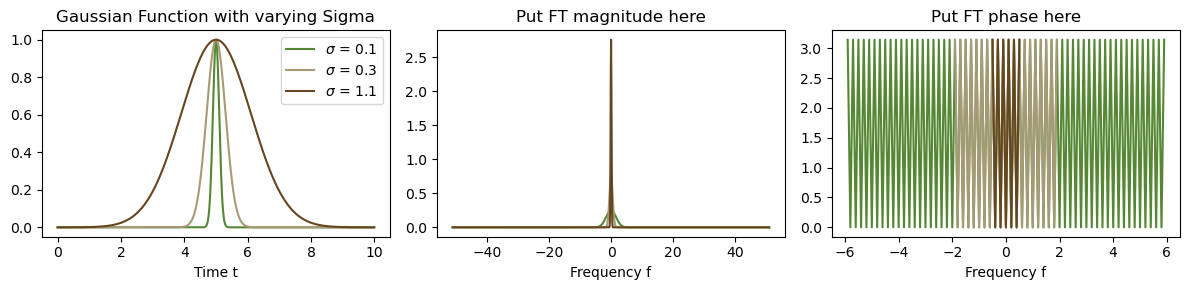

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Gaussian Function with varying Sigma")
ax[0].set_xlabel("Time t")
ax[0].plot(t, gauss1, label=r"$\sigma$ = 0.1", color="#558734")
ax[0].plot(t, gauss2, label=r"$\sigma$ = 0.3", color="#a79a77")
ax[0].plot(t, gauss3, label=r"$\sigma$ = 1.1", color="#65461f")
ax[0].legend()

ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
ax[1].plot(freq, FT_mag1, color="#558734")
ax[1].plot(freq, FT_mag2, color="#a79a77")
ax[1].plot(freq, FT_mag3, color="#65461f")

ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
ax[2].plot(freq, FT_phase1, color="#558734")
ax[2].plot(freq, FT_phase2, color="#a79a77")
ax[2].plot(freq, FT_phase3, color="#65461f")

#fig.savefig("010_FourierTransform.png")
fig.tight_layout()

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


In [5]:
#Make a wave (cosine or sine) - you can do combo of waves
N2 = 500
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(N2)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]

signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

(0.0, 0.3)

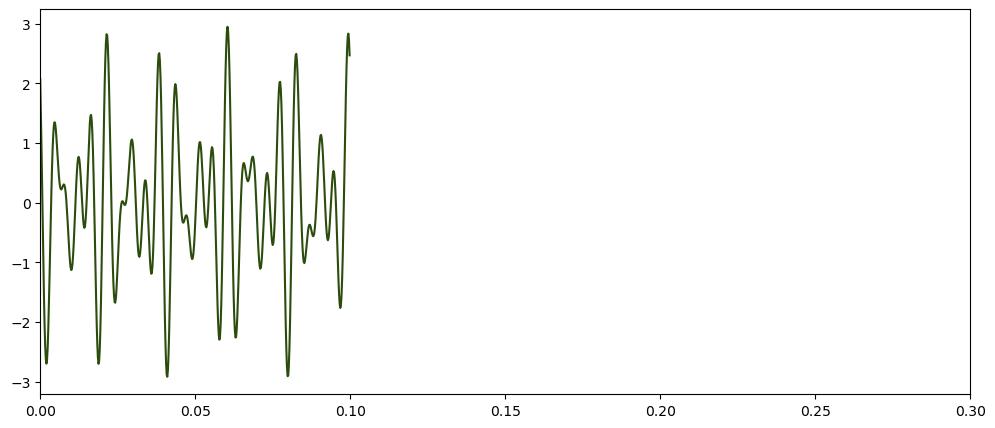

In [6]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original, color="#2b4c0c")
ax.set_xlim(0,0.3)

In [7]:
#FILL: Plot the fourier transform of the clean, original signal
# Frequency Axis
freq = np.fft.fftshift(np.fft.fftfreq(N2, dt))
clean = np.abs(np.fft.fftshift(np.fft.fft(signal_original)))

Text(0.5, 1.0, 'Fourier Transform of the Clean Signal')

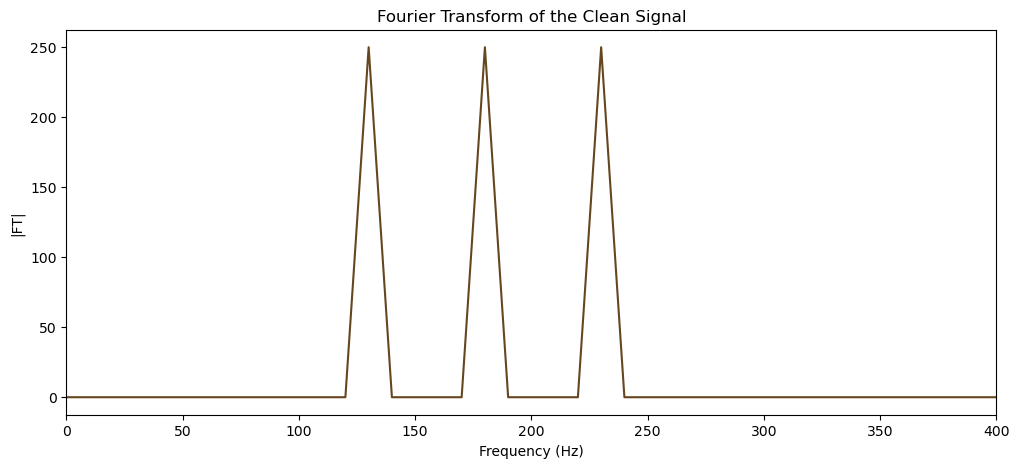

In [8]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(freq, clean, color="#65461f")
ax.set_xlim(0,400)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("|FT|")
ax.set_title("Fourier Transform of the Clean Signal")
#fig.savefig("010_FourierTransformCleanSignal.png")

In [9]:
rng = np.random.default_rng()

#Define parameters of Gaussian noise)
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point
#Noisy data here
noisy_data = signal_original + noise*5

(0.0, 0.3)

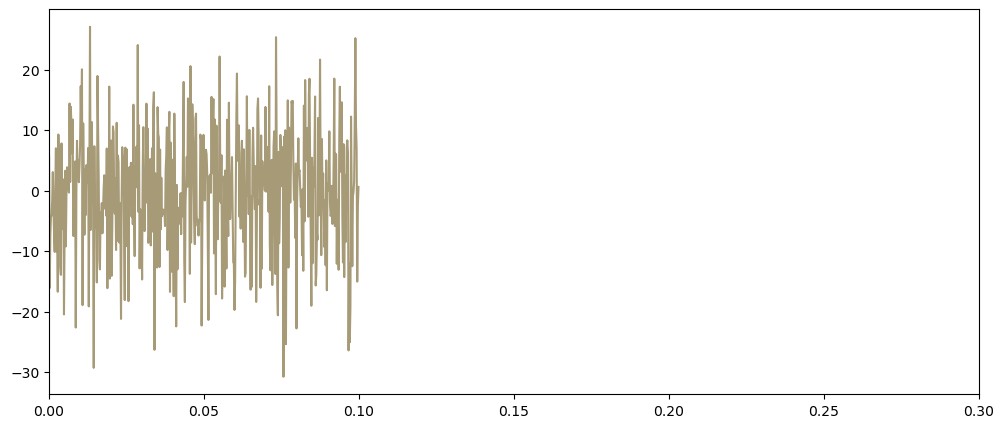

In [10]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, noisy_data, color = "#a79a77")
ax.set_xlim(0,0.3)

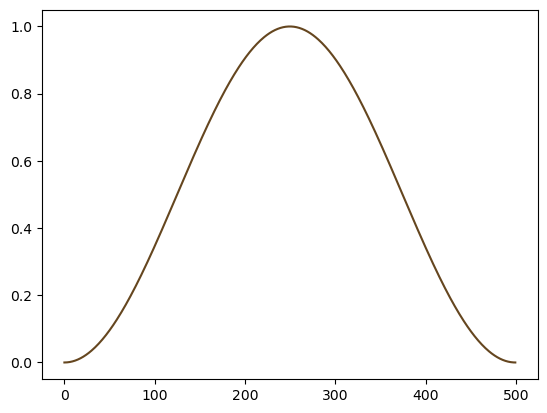

In [11]:
window = np.hanning(len(noisy_data)) #Create a window the size of the data length
plt.plot(window, color = "#65461f")

In [12]:
#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N2, dt))

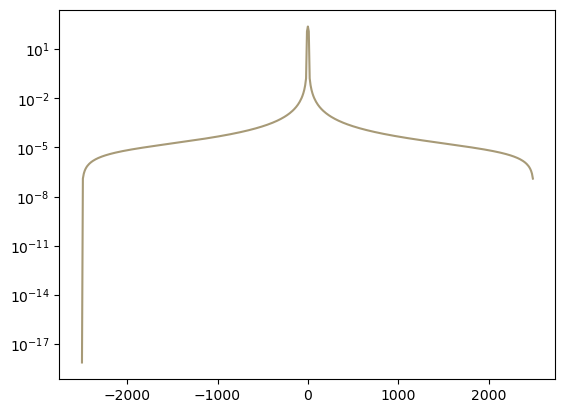

In [13]:
plt.plot(windowSigFreqs, windowSigPeaks, color = "#a79a77")
plt.yscale('log')

In [14]:
noisyFourier = np.fft.fft(noisy_data*window)
noisySigPeaks = np.abs(np.fft.fftshift(np.fft.fft(noisy_data*window)))

Text(0.5, 1.0, 'Fourier Transform of noisy signal (Hann windowed)')

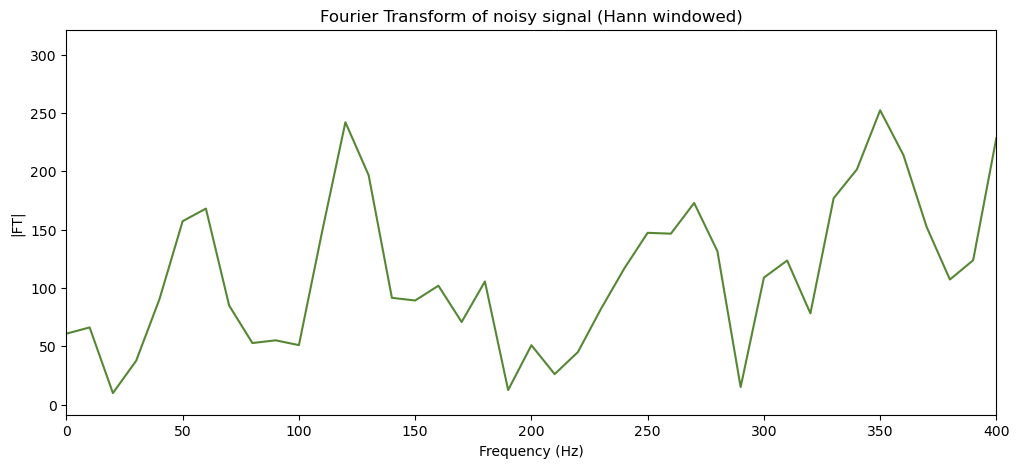

In [15]:
# Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window
noisySigPeaks = np.abs(np.fft.fftshift(noisyFourier))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(freq, noisySigPeaks, color="#558734")
ax.set_xlim(0,400)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("|FT|")
ax.set_title("Fourier Transform of noisy signal (Hann windowed)")
#fig.savefig("010_FourierTransformNoisySignal.png")

In [16]:
# Fill: Find a suitable threshold value to filter the noise in fourier space
noisyMag = np.abs(noisyFourier)
threshold = 0.6 * noisyMag.max()
mask = noisyMag > threshold

cleanFourier = noisyFourier * mask

# We print the filtered
print("Frequencies retained: ", np.fft.fftfreq(N2, dt)[mask])

Frequencies retained:  [  120.   130.   340.   350.   360.   400.   560.   570.   580.   590.
   700.   710.   760.   930.   940.  1080.  1150.  1160.  1230.  1300.
  1310.  1440.  1460.  1470.  1610.  1760.  1770.  1780.  1960.  1980.
  2030.  2160.  2220.  2320.  2330.  2480. -2480. -2330. -2320. -2220.
 -2160. -2030. -1980. -1960. -1780. -1770. -1760. -1610. -1470. -1460.
 -1440. -1310. -1300. -1230. -1160. -1150. -1080.  -940.  -930.  -760.
  -710.  -700.  -590.  -580.  -570.  -560.  -400.  -360.  -350.  -340.
  -130.  -120.]


In [17]:
# Fill: with the cleaned signal in fourier space, convert it back to the time domain
recoveredSignal = np.real(np.fft.ifft(cleanFourier))

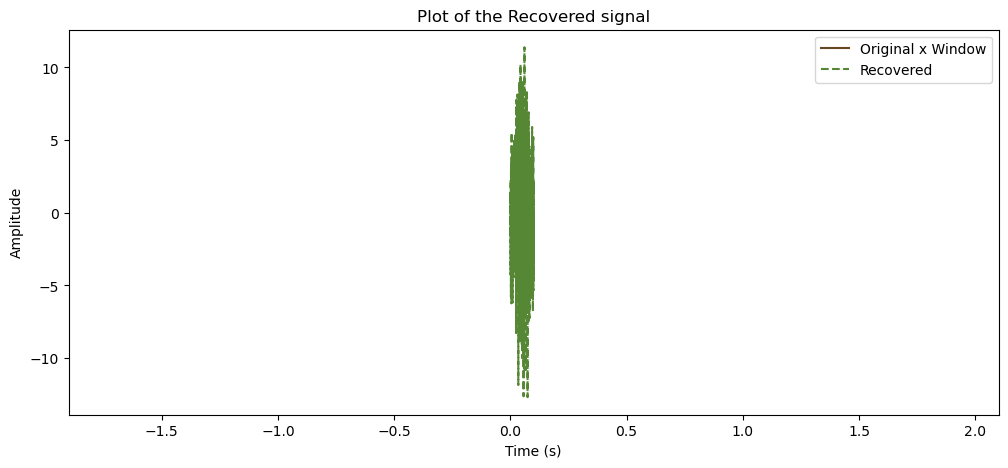

In [43]:
# Plot the recovered signal
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original*window, label="Original x Window", color="#65461f")
ax.plot(t_, recoveredSignal, "--", label="Recovered", color="#558734")
ax.set_xlim(-1.9,2.1)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude")
ax.set_title("Plot of the Recovered signal")
ax.legend()
#fig.savefig("010_FourierTransformRecoveredSignal.png")

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

In [19]:
f_signal = 7
duration = 2

# "true" signal (very fine sampling, acts as continuous)
t_true = np.linspace(0, duration, 5000, endpoint=False)
y_true = np.sin(2*np.pi*f_signal*t_true)

# good sampling: fs = 50 Hz > 14 Hz
fs_good = 50
t_good = np.arange(int(duration*fs_good)) / fs_good
y_good = np.sin(2*np.pi*f_signal*t_good)

# aliased sampling: fs = 10 Hz < 14 Hz
fs_bad = 10
t_bad = np.arange(int(duration*fs_bad)) / fs_bad
y_bad = np.sin(2*np.pi*f_signal*t_bad)

# predicted alias: |f_signal - fs_bad| = 3 Hz
y_alias = -np.sin(2*np.pi*f_signal*t_bad)

In [20]:
# Fourier Transform
freq_good = np.fft.fftshift(np.fft.fftfreq(len(t_good), 1/fs_good))
mag_good = np.abs(np.fft.fftshift(np.fft.fft(y_good)))

freq_bad = np.fft.fftshift(np.fft.fftfreq(len(t_bad), 1/fs_bad))
mag_bad = np.abs(np.fft.fftshift(np.fft.fft(y_bad)))

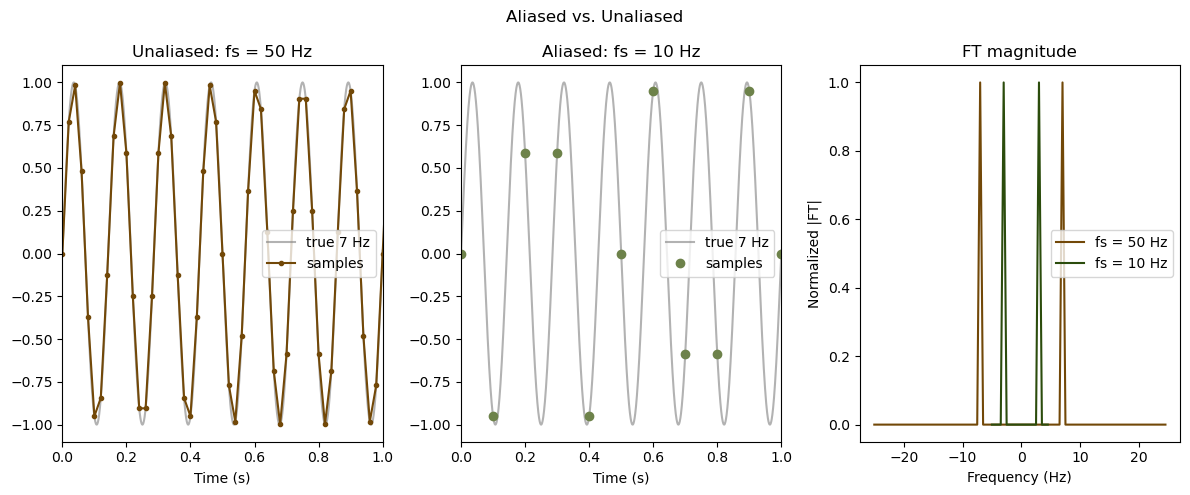

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(12, 5))

# --- Panel 1: Non-aliased sampling ---
ax[0].set_title("Unaliased: fs = 50 Hz")
ax[0].plot(t_true, y_true, color="gray", alpha=0.6, label="true 7 Hz")
ax[0].plot(t_good, y_good, "o-", color="#724808", ms=3, label="samples")
ax[0].set_xlim(0, 1)
ax[0].set_xlabel("Time (s)")
ax[0].legend()

# --- Panel 2: Aliased sampling ---
ax[1].set_title("Aliased: fs = 10 Hz")
ax[1].plot(t_true, y_true, color="gray", alpha=0.6, label="true 7 Hz")
ax[1].plot(t_bad, y_bad, "o", color="#6d824a", label="samples")
ax[1].set_xlim(0, 1)
ax[1].set_xlabel("Time (s)")
ax[1].legend()

# --- Panel 3: FT magnitude ---
ax[2].set_title("FT magnitude")
ax[2].plot(freq_good, mag_good/mag_good.max(), color="#724808", label="fs = 50 Hz")
ax[2].plot(freq_bad, mag_bad/mag_bad.max(), color="#2b4c0c", label="fs = 10 Hz")
ax[2].set_xlabel("Frequency (Hz)")
ax[2].set_ylabel("Normalized |FT|")
ax[2].legend()

fig.suptitle("Aliased vs. Unaliased")
fig.tight_layout()
#fig.savefig("010_FourierTransformAliasedvsUnaliased.png")
plt.show()

#### Problem code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
## Section 3: Notes

In [22]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

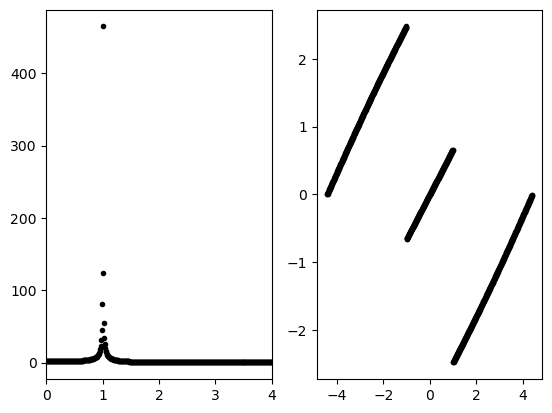

In [23]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [24]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

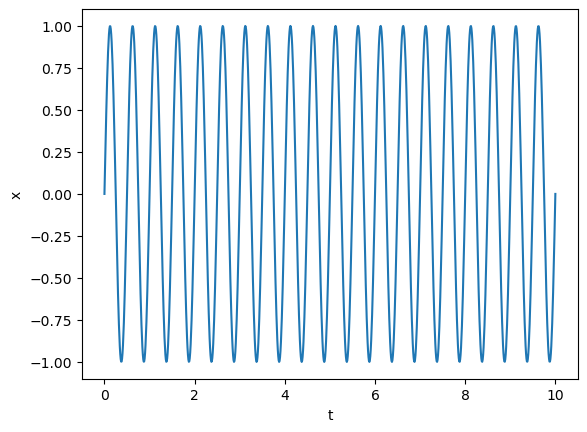

In [25]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [26]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

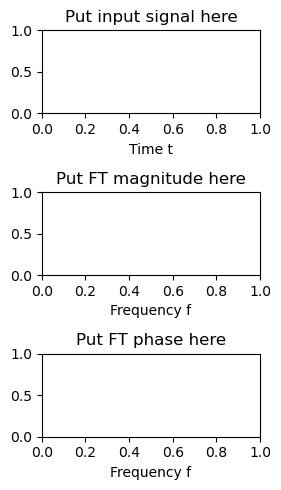

In [27]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

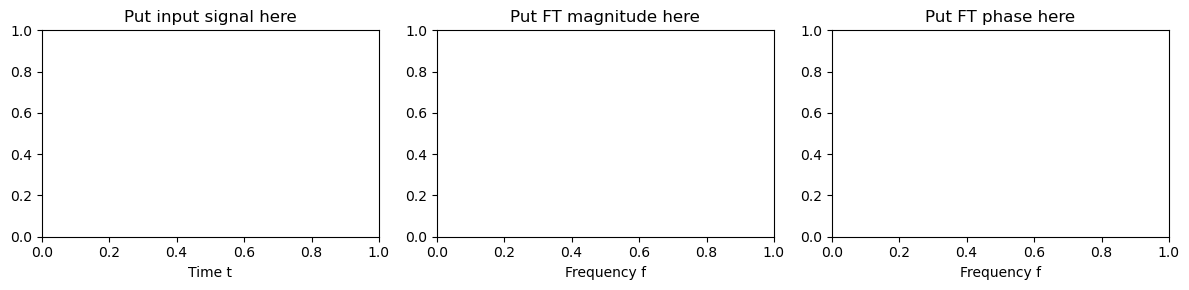

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

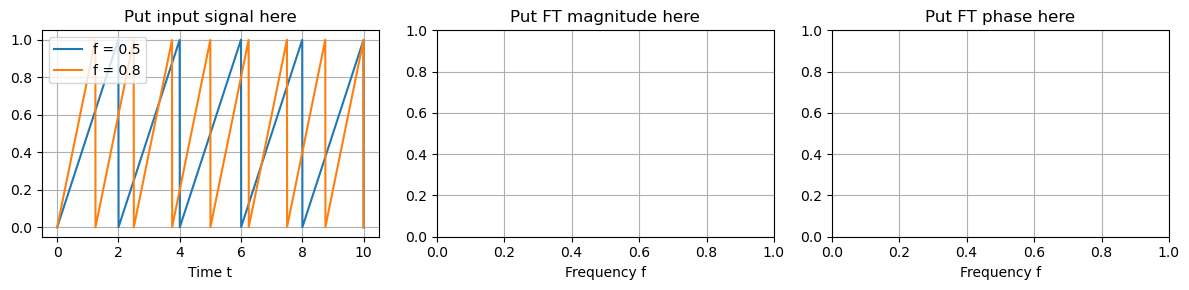

In [29]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [30]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]

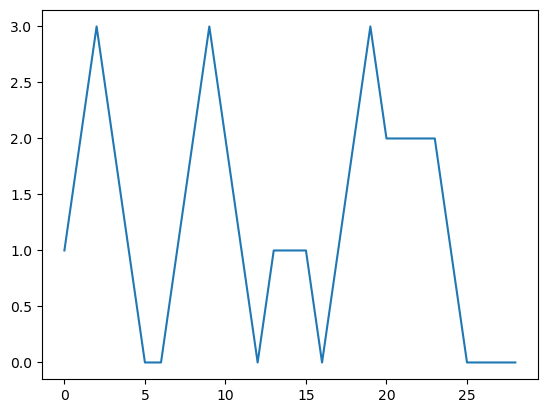

In [31]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [32]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [33]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

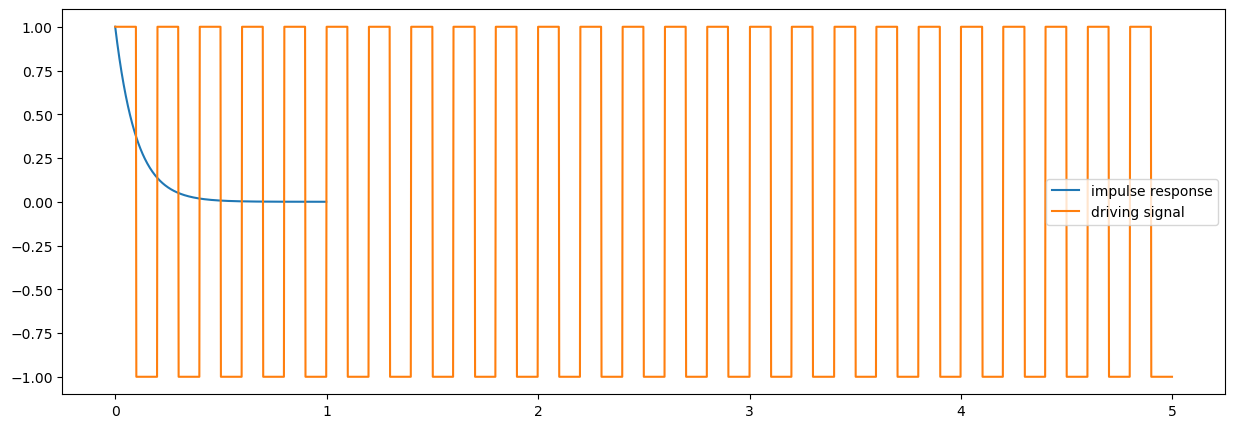

In [34]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [35]:
response = np.convolve(input_signal, h_t, mode = "same")

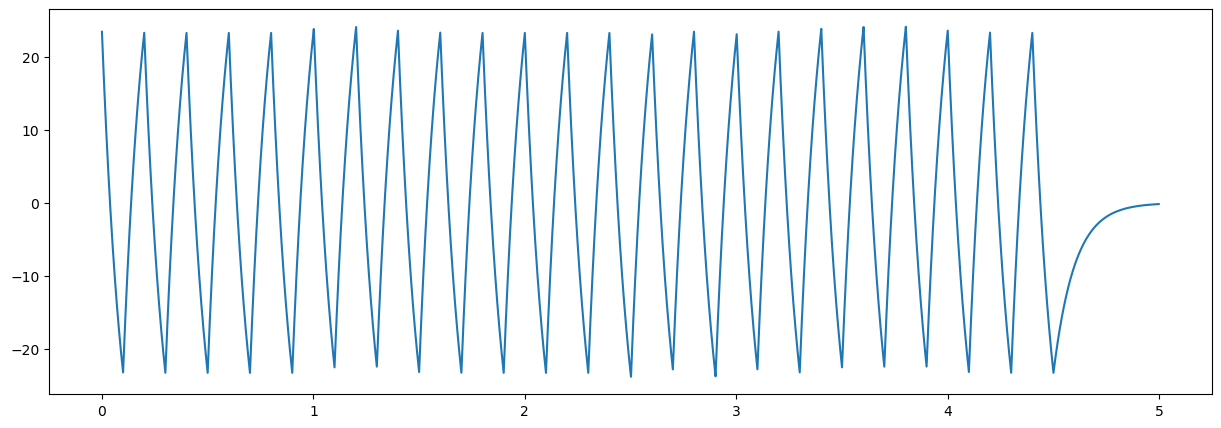

In [36]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [37]:
fourier_length = len(h_t) + len(input_signal) - 1

In [38]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [39]:
fourier_response = fourier_h*fourier_input 

In [40]:
response = np.real(np.fft.ifft(fourier_response))

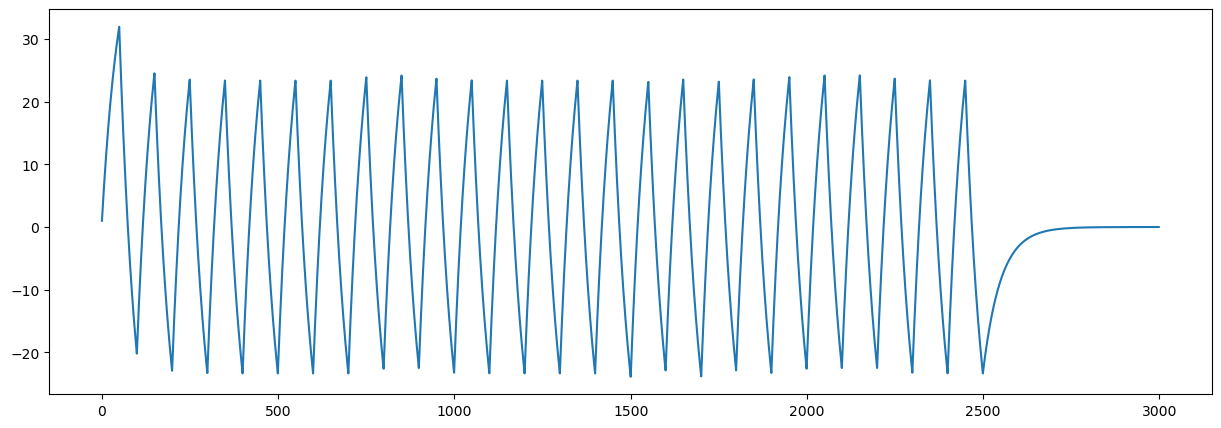

In [41]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)